In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import ops
from keras import Input
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense, SimpleRNN

import numpy as np

import pandas

keras.utils.set_random_seed(42)

In [ ]:
dataframe_raw = pandas.read_csv('ensino_unificado.csv', delimiter=';', usecols=["ANO","REGIAO","UF","CÓDIGO DO MUNICIPIO","REDE","CÓDIGO DA ESCOLA","Aprovação no 1º Ano do Ensino Fundamental"])



<Axes: >

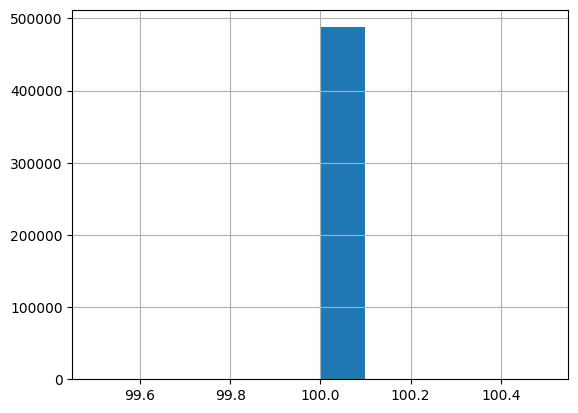

In [ ]:
import matplotlib.pyplot as plt

# Filtrando o dataframe para o período de interesse
dataframe_filtrado = dataframe_raw[(dataframe_raw["ANO"] >= 2014) & (dataframe_raw["ANO"] <= 2019)]

# 1. Calcular Q1 (25%) e Q3 (75%)
Q1 = dataframe_filtrado['Aprovação no 1º Ano do Ensino Fundamental'].quantile(0.25)
Q3 = dataframe_filtrado['Aprovação no 1º Ano do Ensino Fundamental'].quantile(0.75)

# 2. Calcular o IQR (Amplitude Interquartil)
IQR = Q3 - Q1

# 3. Definir os limites inferior e superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 4. Filtrar o DataFrame mantendo apenas os valores dentro dos limites
dataframe_filtrado = dataframe_filtrado[
    (dataframe_filtrado['Aprovação no 1º Ano do Ensino Fundamental'] >= limite_inferior) & (dataframe_filtrado['Aprovação no 1º Ano do Ensino Fundamental'] <= limite_superior)
]




dataframe_filtrado["Aprovação no 1º Ano do Ensino Fundamental"].hist()


Análise dos dados

,ANO,mean,median,std
0,2014,100.0,100.0,0.0
1,2015,100.0,100.0,0.0
2,2016,100.0,100.0,0.0
3,2017,100.0,100.0,0.0
4,2018,100.0,100.0,0.0
5,2019,100.0,100.0,0.0


/tmp/ipykernel_508/1455513259.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")


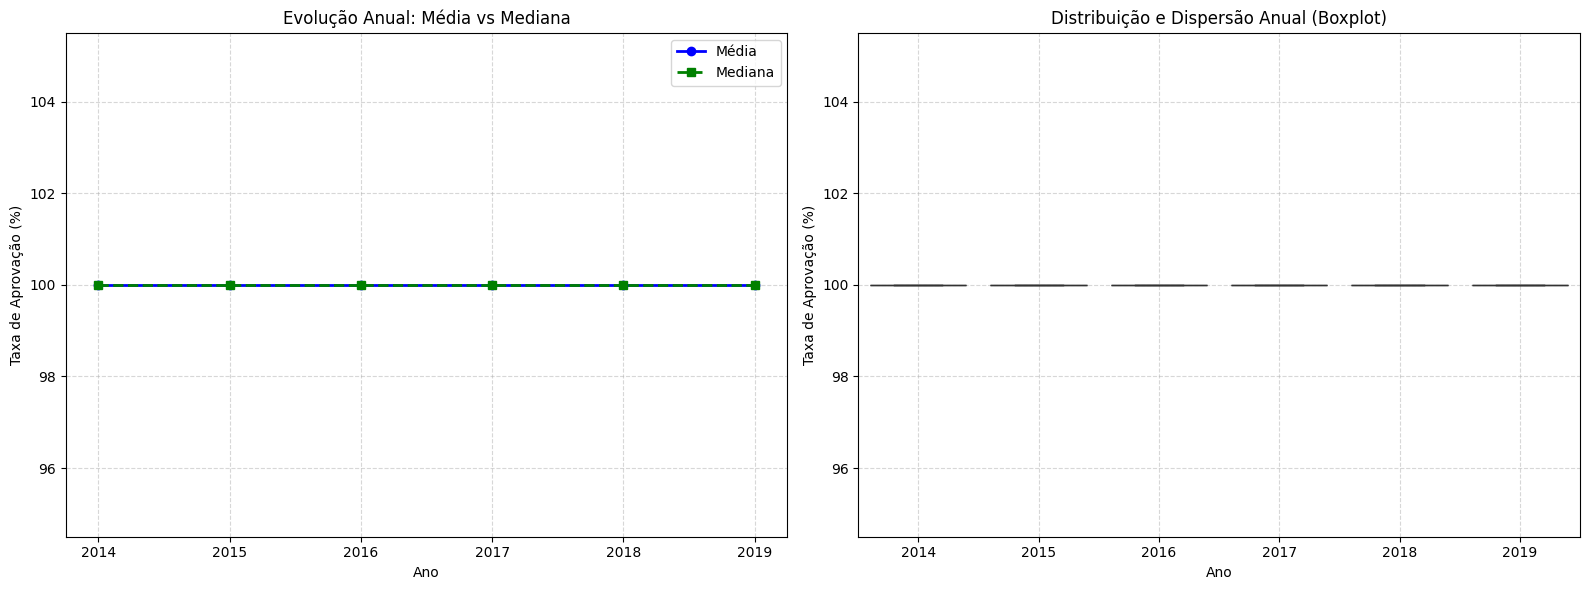

In [ ]:
# 1. Calculando métricas anuais robustas (Média e Mediana)
stats_anuais = dataframe_filtrado.groupby("ANO")["Aprovação no 1º Ano do Ensino Fundamental"].agg(["mean", "median", "std"]).reset_index()
display(stats_anuais)

# 2. Criando subplots para avaliar a variação anual de forma robusta
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Linha comparativa de Média vs Mediana
axes[0].plot(stats_anuais["ANO"], stats_anuais["mean"], marker='o', label='Média', color='blue', linewidth=2)
axes[0].plot(stats_anuais["ANO"], stats_anuais["median"], marker='s', label='Mediana', color='green', linewidth=2, linestyle='--')
axes[0].set_title("Evolução Anual: Média vs Mediana")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Taxa de Aprovação (%)")
axes[0].set_xticks(stats_anuais["ANO"])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Subplot 2: Boxplot para visualizar a distribuição e assimetria (skewness)
sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")
axes[1].set_title("Distribuição e Dispersão Anual (Boxplot)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Taxa de Aprovação (%)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
dataframe_normalizado = dataframe_filtrado.copy()

dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]/100


dataframe_pivotado = dataframe_normalizado.pivot_table(
    values="Aprovação no 1º Ano do Ensino Fundamental",
    index=["REGIAO","UF","CÓDIGO DO MUNICIPIO","REDE","CÓDIGO DA ESCOLA"],
    columns="ANO"
)

dataframe_pivotado.reset_index(inplace=True)
dataframe_pivotado.dropna(inplace=True)


dataframe_pivotado.rename(
    columns={
        "CÓDIGO DO MUNICIPIO":"codigo_municipio",
        "CÓDIGO DA ESCOLA":"codigo_escola",
        "REDE":"rede",
        "REGIAO":"regiao",
        "UF":"uf"
    },
    inplace=True
)
dataframe_pivotado.head()

#dataframe_pivotado.count()

ANO,regiao,uf,codigo_municipio,rede,codigo_escola,2014,2015,2016,2017,2018,2019
13256,Nordeste,AL,2700102,Municipal,27000281,13.815510,13.815510,13.815510,3.705409,13.815510,13.815510
13257,Nordeste,AL,2700102,Municipal,27000400,13.815510,3.102603,13.815510,13.815510,13.815510,3.346803
13258,Nordeste,AL,2700102,Municipal,27000435,3.204413,2.944439,1.502856,2.325907,3.102603,2.633713
13259,Nordeste,AL,2700102,Municipal,27000613,13.815510,2.843852,2.402267,3.152319,13.815510,13.815510
13260,Nordeste,AL,2700102,Municipal,27046427,3.705409,13.815510,3.663562,3.102603,13.815510,3.748992


In [ ]:
dados = dataframe_pivotado[[2014, 2015, 2016, 2017, 2018, 2019]].to_numpy(dtype="float32")

# Features: 2014-2018
X = dados[:, :-1]

# Target: 2019
y = dados[:, -1:]

X = np.expand_dims(X, axis=-1)

dataset_train, dataset_test = keras.utils.split_dataset(
    (X, y),
    left_size=0.7,
    shuffle=True,
    seed=42
)

dataset_train = dataset_train.batch(24)
dataset_test = dataset_test.batch(24)


In [ ]:
model = keras.Sequential([
    keras.Input(shape=(5, 1)),
    keras.layers.SimpleRNN(units=16,return_sequences=True),
    keras.layers.Dense(units=1,activation="linear")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.MeanAbsoluteError()]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 5, 16)          │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5, 1)           │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    dataset_train,
    validation_data=dataset_test,
    epochs=20
)

Epoch 1/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 16.6633 - mean_absolute_error: 2.8773 - val_loss: 17.1098 - val_mean_absolute_error: 2.8883
Epoch 2/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 16.6304 - mean_absolute_error: 2.8730 - val_loss: 17.0672 - val_mean_absolute_error: 2.8913
Epoch 3/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 16.6079 - mean_absolute_error: 2.8709 - val_loss: 17.0506 - val_mean_absolute_error: 2.8936
Epoch 4/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 16.5956 - mean_absolute_error: 2.8696 - val_loss: 17.0398 - val_mean_absolute_error: 2.8944
Epoch 5/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 16.5862 - mean_absolute_error: 2.8686 - val_loss: 17.0324 - val_mean_absolute_error: 2.8944
Epoch 6/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 16.5789 - mean_absolute_error: 2.8680 - val_loss: 17.0268 - val_mean_absolute_error: 2.8939
Epoch 7/20
1763/1763 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 16.5727 - mean

#VALIDACAO

In [ ]:
X_train_validacao = np.concatenate([
    x.numpy() for x, y in dataset_train
], axis=0)

y_train_validacao = np.concatenate([
    y.numpy() for x, y in dataset_train
], axis=0).reshape(-1)


X_test_validacao = np.concatenate([
    x.numpy() for x, y in dataset_test
], axis=0)

y_test_validacao = np.concatenate([
    y.numpy() for x, y in dataset_test
], axis=0).reshape(-1)


# ----------------------------------------------------------
# Previsão da RNN JÁ TREINADA
# ----------------------------------------------------------

previsoes_rnn_completas = model.predict(
    X_test_validacao,
    verbose=0
)

# Seu modelo está com return_sequences=True.
# Portanto a saída tem formato:
#
# (amostras, 5 timesteps, 1 saída)
#
# Para prever 2019, usamos somente a saída do
# último timestep (após observar 2018).

previsao_rnn = previsoes_rnn_completas[:, -1, 0]


# ----------------------------------------------------------
# Baselines
# ----------------------------------------------------------

# 1. Sempre prever a média de 2019 observada no TREINO
previsao_media = np.full(
    len(y_test_validacao),
    np.mean(y_train_validacao)
)


# 2. Sempre prever a mediana de 2019 observada no TREINO
previsao_mediana = np.full(
    len(y_test_validacao),
    np.median(y_train_validacao)
)


# 3. Persistência:
# "2019 será igual a 2018"
previsao_ultimo_ano = X_test_validacao[:, -1, 0]


# 4. Média dos 5 anos anteriores
# 2014, 2015, 2016, 2017 e 2018
previsao_media_5_anos = np.mean(
    X_test_validacao[:, :, 0],
    axis=1
)


# ----------------------------------------------------------
# Métricas
# ----------------------------------------------------------

def calcular_mae(real, previsto):
    return np.mean(np.abs(real - previsto))


def calcular_rmse(real, previsto):
    return np.sqrt(
        np.mean((real - previsto) ** 2)
    )


def calcular_r2(real, previsto):

    soma_residuos = np.sum(
        (real - previsto) ** 2
    )

    soma_total = np.sum(
        (real - np.mean(real)) ** 2
    )

    return 1 - (soma_residuos / soma_total)


# ----------------------------------------------------------
# Comparação
# ----------------------------------------------------------

modelos = {
    "RNN": previsao_rnn,
    "Média do treino": previsao_media,
    "Mediana do treino": previsao_mediana,
    "Último ano (2018)": previsao_ultimo_ano,
    "Média dos 5 anos": previsao_media_5_anos
}


resultados = []

for nome, previsao in modelos.items():

    resultados.append({

        "Modelo": nome,

        # Dados estão normalizados entre 0 e 1.
        # Multiplicando por 100, o erro volta
        # para pontos percentuais.
        "MAE (p.p.)": calcular_mae(
            y_test_validacao,
            previsao
        ) * 100,

        "RMSE (p.p.)": calcular_rmse(
            y_test_validacao,
            previsao
        ) * 100,

        "R²": calcular_r2(
            y_test_validacao,
            previsao
        )
    })


resultado_validacao = pd.DataFrame(resultados)

resultado_validacao = resultado_validacao.sort_values(
    "MAE (p.p.)"
).reset_index(drop=True)

display(
    resultado_validacao.round(4)
)


# ----------------------------------------------------------
# Quanto a RNN melhora em relação à persistência?
# ----------------------------------------------------------

mae_rnn = calcular_mae(
    y_test_validacao,
    previsao_rnn
)

mae_persistencia = calcular_mae(
    y_test_validacao,
    previsao_ultimo_ano
)

skill_rnn = 1 - (
    mae_rnn / mae_persistencia
)

print(
    f"Melhoria da RNN sobre o baseline "
    f"'2019 = 2018': {skill_rnn:.2%}"
)

,Modelo,MAE (p.p.),RMSE (p.p.),R²
0,Mediana do treino,213.679596,496.187988,-0.2277
1,Último ano (2018),232.377197,514.608215,-0.3205
2,Média dos 5 anos,261.977600,427.717712,0.0878
3,RNN,270.228790,393.282715,0.2287
4,Média do treino,342.102600,447.856598,-0.0002


Melhoria da RNN sobre o baseline '2019 = 2018': -16.29%
